# THƯ VIỆN

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# TẢI DỮ LIỆU

In [2]:
path = 'C:\\Users\\Admin\\Downloads\\AB_Testing\\DataSet\\marketing_AB.csv'
data_mar = pd.read_csv(path)
print(data_mar)


        user id test group  converted  total ads most ads day  most ads hour
0       1069124         ad      False        130       Monday             20
1       1119715         ad      False         93      Tuesday             22
2       1144181         ad      False         21      Tuesday             18
3       1435133         ad      False        355      Tuesday             10
4       1015700         ad      False        276       Friday             14
...         ...        ...        ...        ...          ...            ...
588096  1278437         ad      False          1      Tuesday             23
588097  1327975         ad      False          1      Tuesday             23
588098  1038442         ad      False          3      Tuesday             23
588099  1496395         ad      False          1      Tuesday             23
588100  1237779         ad      False          1      Tuesday             23

[588101 rows x 6 columns]


# MÔ TẢ DỮ LIỆU

In [3]:
print(data_mar.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 588101 entries, 0 to 588100
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   user id        588101 non-null  int64 
 1   test group     588101 non-null  object
 2   converted      588101 non-null  bool  
 3   total ads      588101 non-null  int64 
 4   most ads day   588101 non-null  object
 5   most ads hour  588101 non-null  int64 
dtypes: bool(1), int64(3), object(2)
memory usage: 23.0+ MB
None


# BẢNG THỐNG KÊ TẦN SỐ

In [4]:
print(data_mar['test group'].value_counts())

test group
ad     564577
psa     23524
Name: count, dtype: int64


In [5]:
print(data_mar['converted'].value_counts())

converted
False    573258
True      14843
Name: count, dtype: int64


In [6]:
print(data_mar['most ads day'].value_counts())

most ads day
Friday       92608
Monday       87073
Sunday       85391
Thursday     82982
Saturday     81660
Wednesday    80908
Tuesday      77479
Name: count, dtype: int64


In [19]:
print(sorted(data_mar['most ads hour'].value_counts().index))

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


# MÃ HÓA CÁC BIẾN ĐỊNH TÍNH

In [20]:
data_mar['converted_encoding'] = data_mar['converted'].map({True: 1, False: 0})

In [22]:
conditions = [
    (data_mar['most ads hour'] >= 0) & (data_mar['most ads hour'] <= 3),
    (data_mar['most ads hour'] >= 4) & (data_mar['most ads hour'] <= 11),
    (data_mar['most ads hour'] > 11) & (data_mar['most ads hour'] <= 13),
    (data_mar['most ads hour'] > 13) & (data_mar['most ads hour'] <= 18),
    (data_mar['most ads hour'] > 18) & (data_mar['most ads hour'] <= 23)
]

labels = ['Khuya', 'Sang', 'Trua', 'Chieu', 'Toi']

data_mar['time_group'] = np.select(
    conditions,
    labels,
    default='Khong xac dinh'
)

print(data_mar)

        user id test group  converted  total ads most ads day  most ads hour  \
0       1069124         ad      False        130       Monday             20   
1       1119715         ad      False         93      Tuesday             22   
2       1144181         ad      False         21      Tuesday             18   
3       1435133         ad      False        355      Tuesday             10   
4       1015700         ad      False        276       Friday             14   
...         ...        ...        ...        ...          ...            ...   
588096  1278437         ad      False          1      Tuesday             23   
588097  1327975         ad      False          1      Tuesday             23   
588098  1038442         ad      False          3      Tuesday             23   
588099  1496395         ad      False          1      Tuesday             23   
588100  1237779         ad      False          1      Tuesday             23   

        converted_encoding time_group  

# KIỂM ĐỊNH TỶ LỆ CHUYỂN ĐỔI THEO NHÓM

In [23]:
print(
    data_mar.groupby('test group')['converted_encoding'].agg(
        successes='sum',
        total='count',
        conversion_rate='mean'
    )
)

            successes   total  conversion_rate
test group                                    
ad              14423  564577         0.025547
psa               420   23524         0.017854


In [24]:
def prob_perm_fun(x, nA, nB, R):
    n = nA + nB
    prop_diff = np.zeros(R)

    for i in range(R):
        idx_a = np.random.choice(n, size=nA, replace=False)
        idx_b = np.setdiff1d(np.arange(n), idx_a)

        prop_diff[i] = np.mean(x[idx_a]) - np.mean(x[idx_b])

    return prop_diff

In [25]:
np.random.seed(44)
diff_prob_perm_mar = prob_perm_fun(x=data_mar['converted_encoding'], nA=564577, nB=23524, R=1000)

In [26]:
prob_ad = data_mar.loc[data_mar['test group'] == 'ad', 'converted_encoding'].mean()
prob_psa = data_mar.loc[data_mar['test group'] == 'psa', 'converted_encoding'].mean()

prob_diff_group = prob_ad - prob_psa

p_value = np.mean(diff_prob_perm_mar > (prob_ad - prob_psa))

print('Ty le Group ad: ', prob_ad)
print('Ty le Grop psa: ', prob_psa)
print("prob_ad - prob_psa: ", prob_diff_group)
print("P-value: ", p_value)

Ty le Group ad:  0.025546559636683747
Ty le Grop psa:  0.01785410644448223
prob_ad - prob_psa:  0.007692453192201517
P-value:  0.0


Tỷ lệ chuyển đổi ở nhóm ad cao hơn tỷ lệ chuyển đổi ở nhóm psa

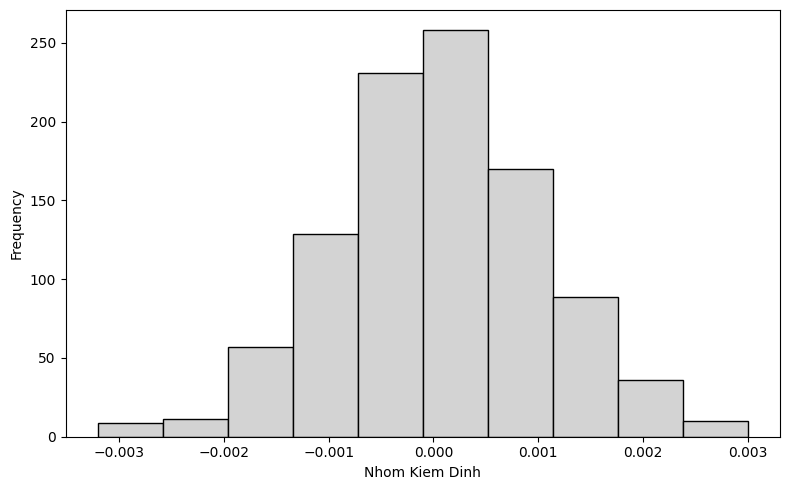

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(
    diff_prob_perm_mar,
    bins=10,
    color="lightgray",
    edgecolor="black"
)

plt.xlabel("Nhom Kiem Dinh")
plt.ylabel("Frequency")

plt.style.use("default")
plt.tight_layout()

# KIỂM ĐỊNH CHÊNH LỆCH TRUNG BÌNH THEO NHÓM

In [28]:
print(
    data_mar.groupby('test group')['total ads'].agg(
        ['count', 'mean', 'std']
    )
)

             count       mean        std
test group                              
ad          564577  24.823365  43.750456
psa          23524  24.761138  42.860720


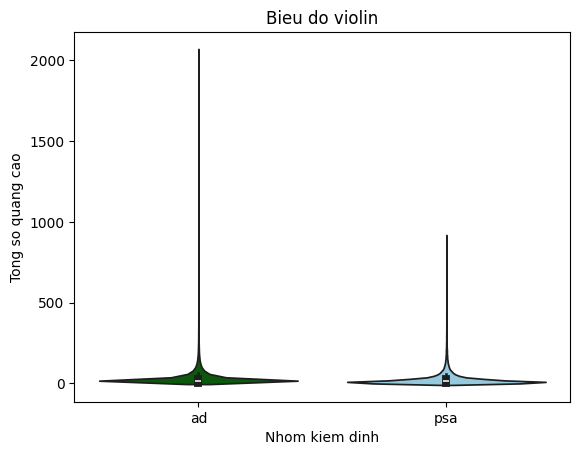

In [29]:
sns.violinplot(
    data = data_mar,
    x = 'test group',
    y = 'total ads',
    hue = 'test group',
    palette = {
        'ad': 'Darkgreen',
        'psa': 'Skyblue'
    },
    inner = 'box',
    legend = False
)

plt.title('Bieu do violin')
plt.xlabel('Nhom kiem dinh')
plt.ylabel('Tong so quang cao')
plt.show()

In [30]:
def perm_fun(x, nA, nB, R):
    n = nA + nB
    mean_diff = np.zeros(R)

    for i in range(R):
        idx_a = np.random.choice(n, size=nA, replace=False)
        idx_b = np.setdiff1d(np.arange(n), idx_a)

        mean_diff[i] = np.mean(x[idx_a]) - np.mean(x[idx_b])

    return mean_diff

In [31]:
np.random.seed(45)
diff_mean_perm = perm_fun(x=data_mar['total ads'], nA=564577, nB=23524, R=1000)

In [32]:
mean_ad = data_mar.loc[data_mar["test group"] == "ad", "total ads"].mean()
mean_psa = data_mar.loc[data_mar["test group"] == "psa", "total ads"].mean()

mean_diff = mean_ad - mean_psa

p_value = np.mean(np.abs(diff_mean_perm) > np.abs(mean_ad - mean_psa))

print("Mean A:", mean_ad)
print("Mean B:", mean_psa)
print("MeanA - MeanB:", mean_diff)
print("P-value:", p_value)

Mean A: 24.823365103431417
Mean B: 24.761137561639178
MeanA - MeanB: 0.06222754179223955
P-value: 0.834


Trung bình tổng số lần quảng cáo xuất hiện ở nhóm 2 là như nhau

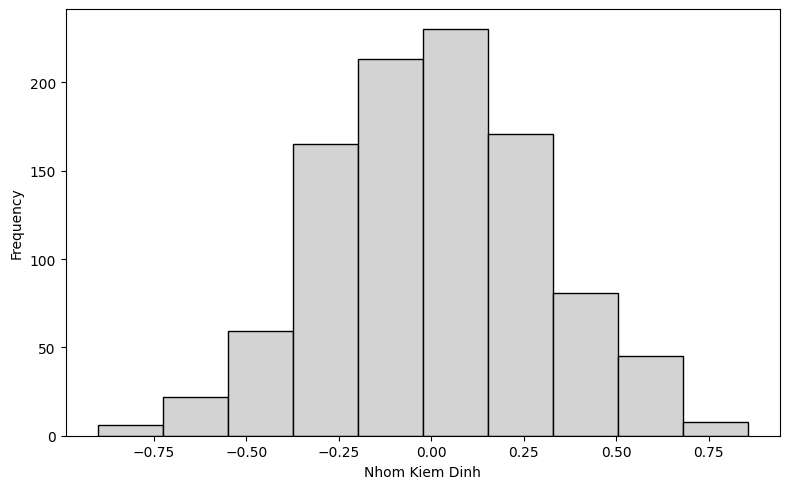

In [35]:
plt.figure(figsize=(8, 5))

plt.hist(
    diff_mean_perm,
    bins=10,
    color="lightgray",
    edgecolor="black"
)

plt.xlabel("Nhom Kiem Dinh")
plt.ylabel("Frequency")

plt.style.use("default")
plt.tight_layout()

# KIỂM ĐỊNH CHÊNH LỆCH TRUNG BÌNH THEO NGÀY

In [36]:
print(
    data_mar.groupby('most ads day')['total ads'].agg(
        ['count', 'mean', 'std']
    )
)

              count       mean        std
most ads day                             
Friday        92608  26.612129  49.562610
Monday        87073  25.328517  46.793732
Saturday      81660  25.227663  41.469519
Sunday        85391  24.403661  38.412048
Thursday      82982  23.428852  42.101261
Tuesday       77479  23.925464  40.554533
Wednesday     80908  24.539205  45.052107


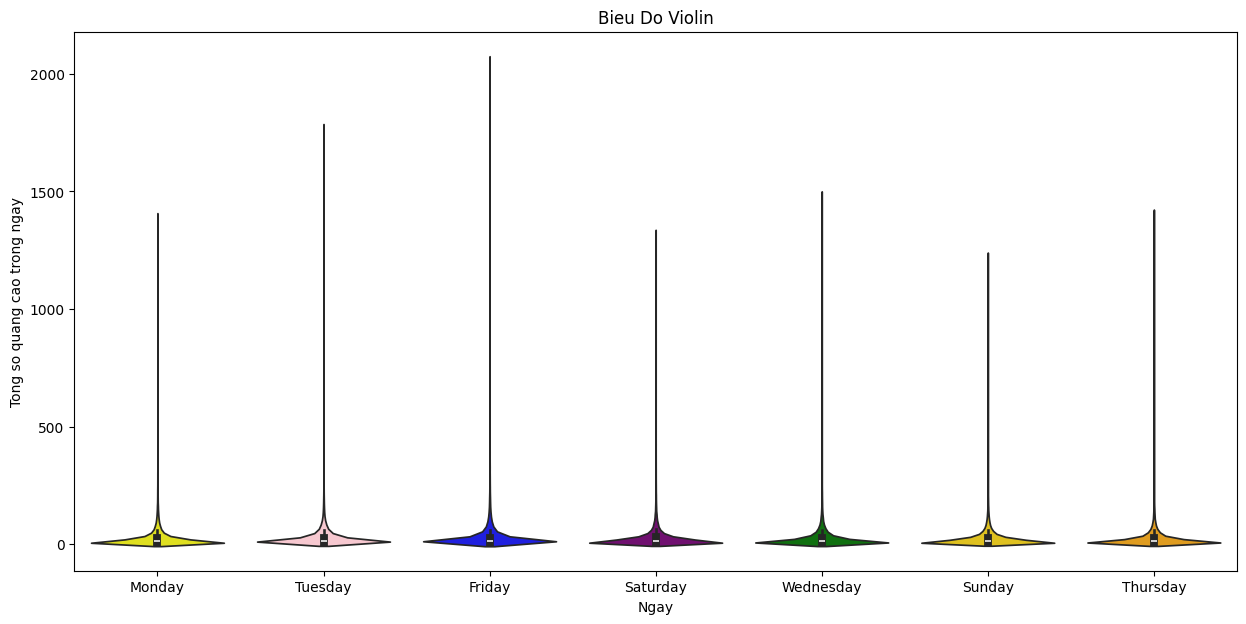

In [46]:
plt.figure(figsize=(15, 7))

sns.violinplot(
    data=data_mar,
    x='most ads day',
    y='total ads',
    hue='most ads day',
    palette={
        'Monday': 'yellow',
        'Tuesday': 'pink',
        'Wednesday': 'green',
        'Thursday': 'orange',
        'Friday': 'blue',
        'Saturday': 'purple',
        'Sunday': 'gold'
    },
    inner='box',
    legend=False
)

plt.title('Bieu Do Violin')
plt.xlabel('Ngay')
plt.ylabel('Tong so quang cao trong ngay')
plt.show()

# KIỂM ĐỊNH CHÊNH LỆCH TRUNG BÌNH THEO GIỜ

In [41]:
print(
    data_mar.groupby('time_group')['total ads'].agg(
        ['count', 'mean', 'std']
    )
)

             count       mean        std
time_group                              
Chieu       195209  24.361013  42.483656
Khuya        18350  23.978910  41.677168
Sang        143740  25.253499  46.889722
Toi         135849  24.415424  40.872998
Trua         94953  25.854170  45.490211


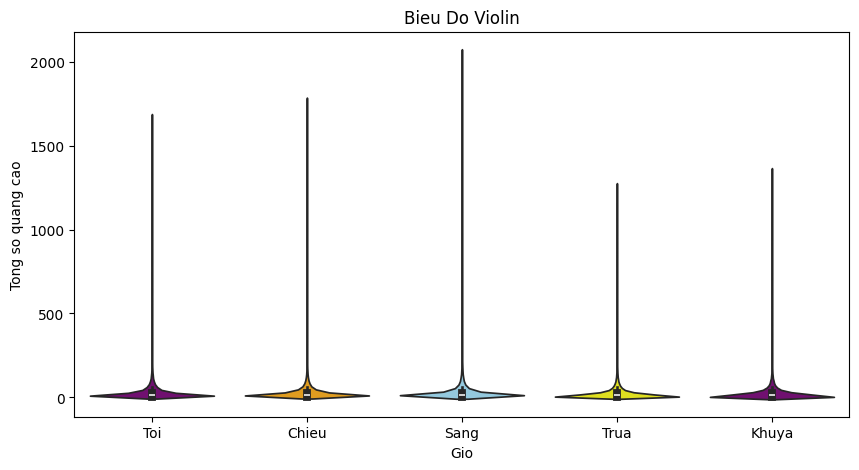

In [44]:
plt.figure(figsize=(10, 5))

sns.violinplot(
    data=data_mar,
    x='time_group',
    y='total ads',
    hue='time_group',
    palette={
        'Chieu': 'orange',
        'Khuya': 'purple',
        'Sang': 'skyblue',
        'Toi': 'purple',
        'Trua': 'yellow'
    },
    inner='box',
    legend=False
)

plt.title('Bieu Do Violin')
plt.xlabel('Gio')
plt.ylabel('Tong so quang cao')
plt.show()